# Tiền xử lý EEG oddball — sub-01 đến sub-05

Notebook này chỉ gọi pipeline và hiển thị kết quả. Code xử lý nằm trong `src/eegproj/preprocessing/` (`io.py`, `channels.py`, `ica.py`, `qc.py`, `pipeline.py`, `verify.py`). Chạy không cần Jupyter: `python scripts/01_preprocess.py`.

Cài đặt: `pip install -r requirements.txt` (đã gồm `pip install -e .`) trong môi trường Python ≥ 3.10 của bạn, rồi chọn kernel của môi trường đó.

Yêu cầu gốc: docs/03_analysis_protocol.md mục 1; tham số: configs/config.yaml. Vai trò và các bước cá nhân: reports/my_preprocessing_role_and_steps.md. Raw được giữ nguyên (ngoại trừ chuyển mã TSV sang UTF-8). ICA mất vài phút mỗi subject.

In [1]:
import os
for var in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(var, '4')

import pandas as pd
from IPython.display import Image, display

from eegproj.config import find_root, load_config
from eegproj.preprocessing import prepare_raw, run, save_epoch_qc, verify_epochs

ROOT = find_root()
CONFIG = load_config(ROOT)
SUBJECTS = CONFIG['dataset']['subjects']
print('Workspace:', ROOT)
print('Subjects:', SUBJECTS)

Workspace: /home/tbm/Documents/EEG_26_27
Subjects: ['01', '02', '03', '04', '05']


## 1. Chuẩn bị dữ liệu raw

- Tải `task-oddball_eeg.json` và tọa độ CapTrak nếu thiếu (chỉ tệp nhỏ, không tải thêm bản ghi EEG hay subject).
- Chuyển các tệp `*.tsv` đang ở Latin-1 (vd. `*_channels.tsv`, `µV` = byte `0xB5`) sang UTF-8, nếu không `mne_bids` báo `UnicodeDecodeError`. Chạy lại nhiều lần vẫn an toàn.

In [2]:
prepare_raw(ROOT, CONFIG);

Fetched 0 metadata file(s); converted 0 TSV file(s) to UTF-8.


## 2. Tiền xử lý 5 subject

Lọc 0.1–40 Hz → nội suy kênh xấu → average reference → ICA (extended infomax) + ICLabel → resample 250 Hz → epoch −0.2–0.8 s, loại PTP > 150 µV. Chi tiết: `src/eegproj/preprocessing/pipeline.py`.

Mặc định bỏ qua subject đã có summary. Đặt `overwrite=True` nếu cần chạy lại. Kiểm tra hình QC trước khi chấp nhận kết quả.

In [3]:
run(ROOT, subjects=SUBJECTS, overwrite=False)

## 3. Kiểm tra dữ liệu đã lưu

Đọc lại FIF và kiểm tra 250 Hz, 251 mẫu, baseline, 3 lớp, peak-to-peak, thứ tự thời gian và 5 block. Kết quả ghi vào `results/preproc_verification.json`.

In [4]:
verify_epochs(ROOT, CONFIG, SUBJECTS);

{'subject': '01', 'epochs': 651, 'channels': 127, 'samples': 251, 'blocks': [0, 1, 2, 3, 4], 'verified': True}
{'subject': '02', 'epochs': 627, 'channels': 127, 'samples': 251, 'blocks': [0, 1, 2, 3, 4], 'verified': True}
{'subject': '03', 'epochs': 629, 'channels': 127, 'samples': 251, 'blocks': [0, 1, 2, 3, 4], 'verified': True}
{'subject': '04', 'epochs': 657, 'channels': 127, 'samples': 251, 'blocks': [0, 1, 2, 3, 4], 'verified': True}
{'subject': '05', 'epochs': 631, 'channels': 127, 'samples': 251, 'blocks': [0, 1, 2, 3, 4], 'verified': True}


## 4. Xem thống kê và hình QC

Hình epoch QC trải trên toàn bộ thời gian thí nghiệm, không chỉ đoạn đầu recording.

,subject,n_channels,sfreq,bad_channels,n_bad_channels,n_ica,ica_iterations,ica_final_weight_change,n_ic_removed,excluded_subject,...,seconds,standard_before,standard_after,standard_retained,target_before,target_after,target_retained,distractor_before,distractor_after,distractor_retained
0,sub-01,127,250.0,NaN,0,35,79,6.000000e-08,6,False,...,56.4,498,491,0.985944,81,80,0.987654,81,80,0.987654
1,sub-02,127,250.0,NaN,0,29,70,6.000000e-08,6,False,...,45.5,498,474,0.951807,81,77,0.950617,81,76,0.938272
2,sub-03,127,250.0,NaN,0,46,72,1.000000e-07,8,False,...,52.4,498,471,0.945783,81,78,0.962963,81,80,0.987654
3,sub-04,127,250.0,NaN,0,26,83,7.000000e-08,2,False,...,36.9,498,496,0.995984,81,80,0.987654,81,81,1.000000
4,sub-05,127,250.0,NaN,0,62,77,9.000000e-08,10,False,...,62.9,498,480,0.963855,81,75,0.925926,81,76,0.938272


sub-01_task-oddball_epoch_qc.png


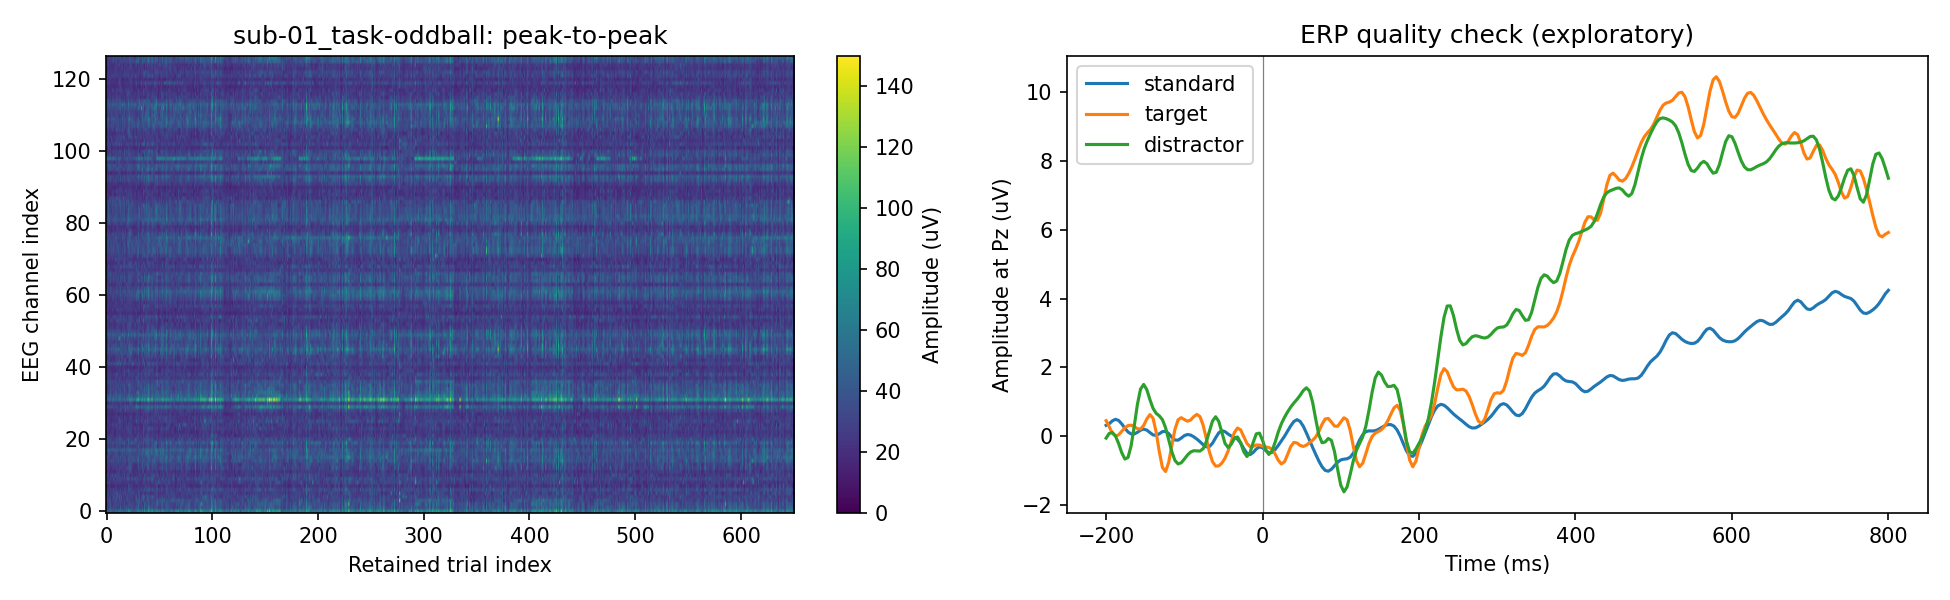

sub-01_task-oddball_excluded_ics_0.png


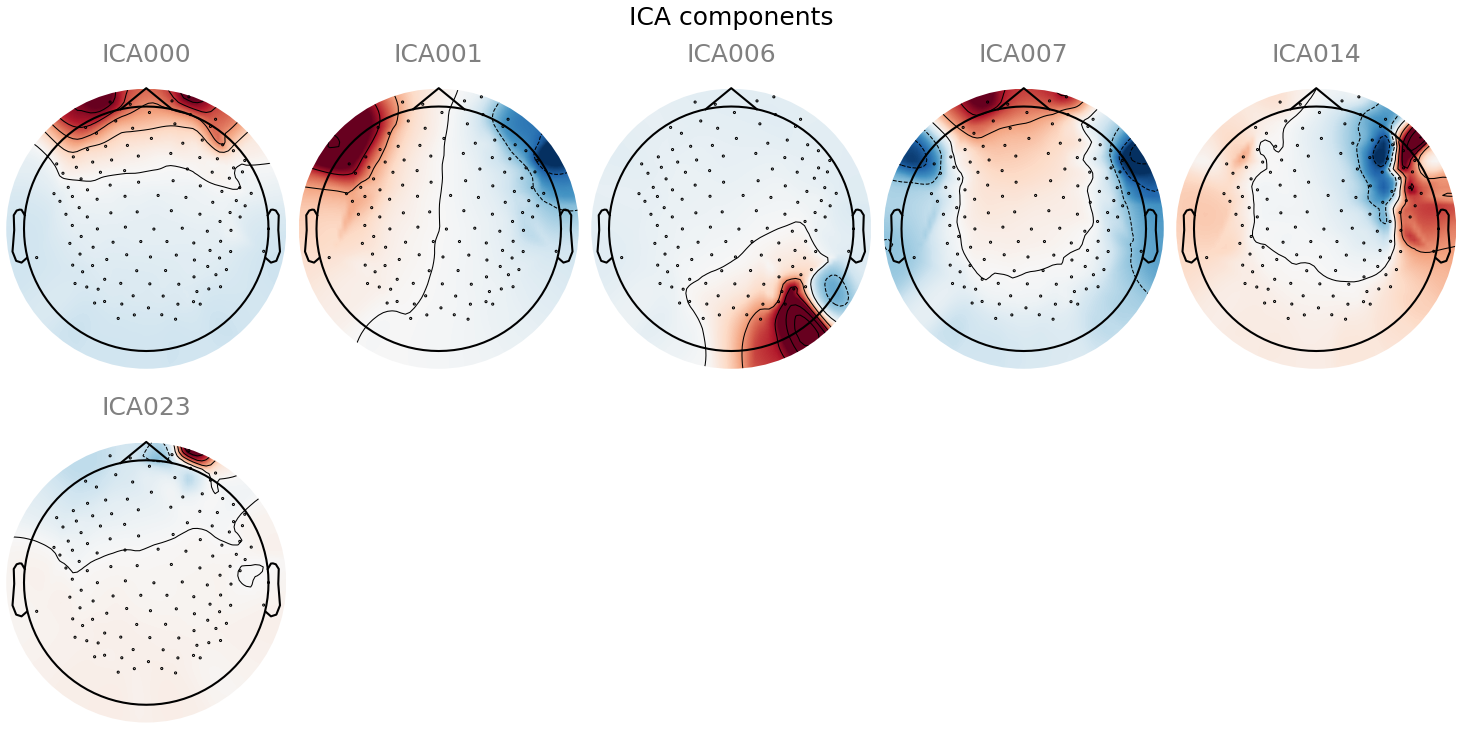

sub-01_task-oddball_qc.png


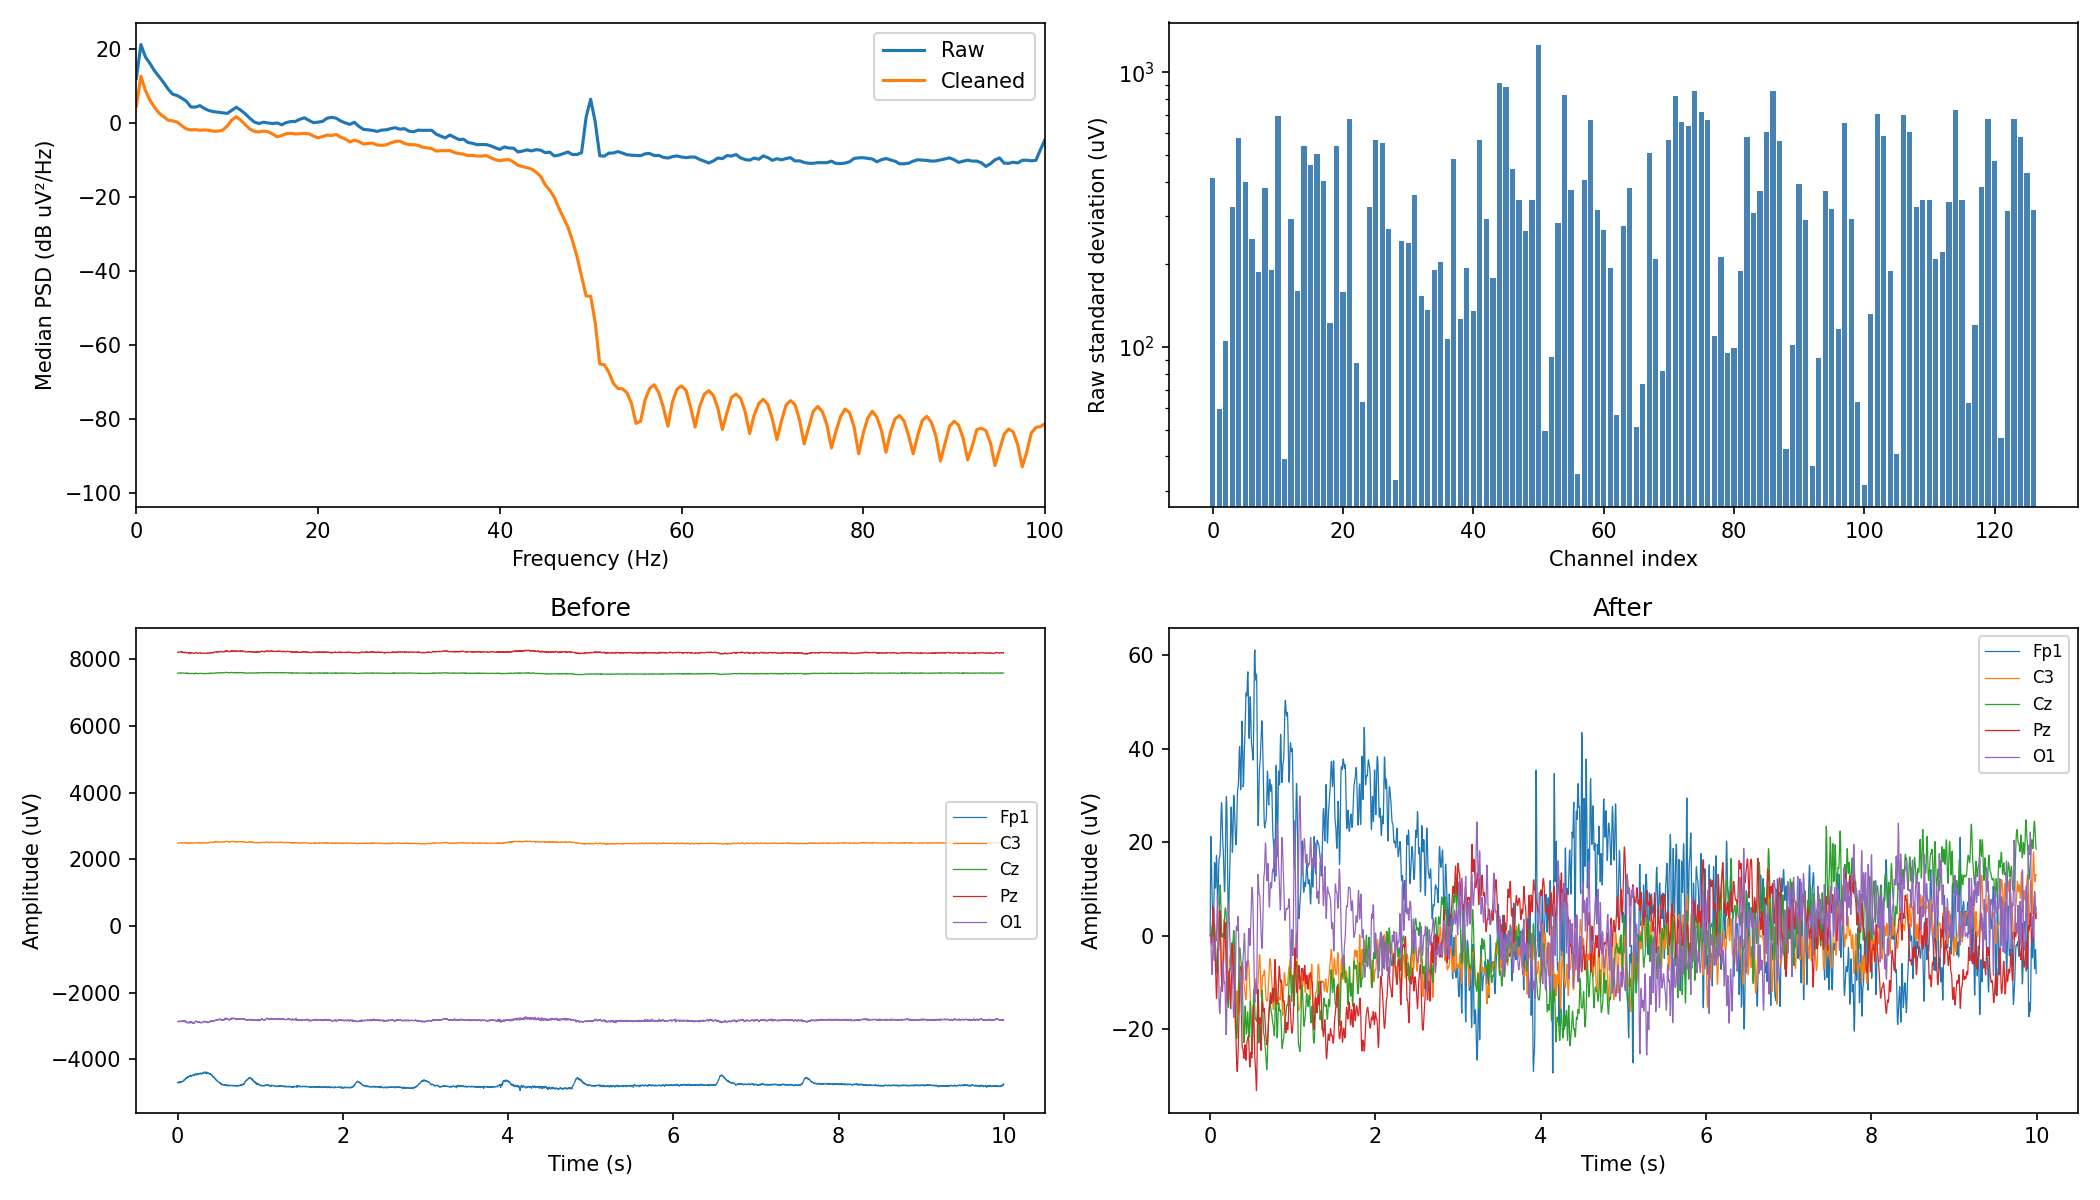

sub-02_task-oddball_epoch_qc.png


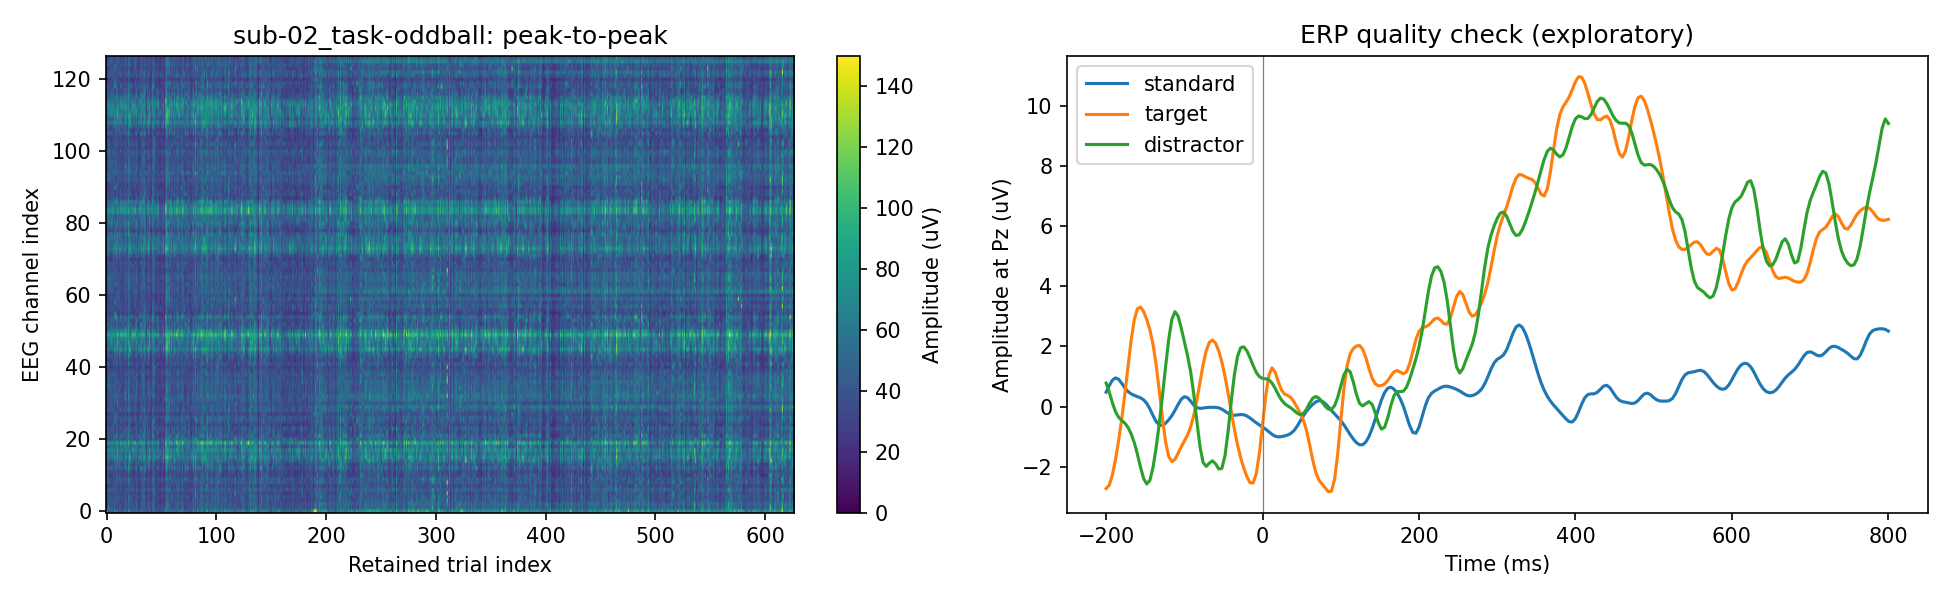

sub-02_task-oddball_excluded_ics_0.png


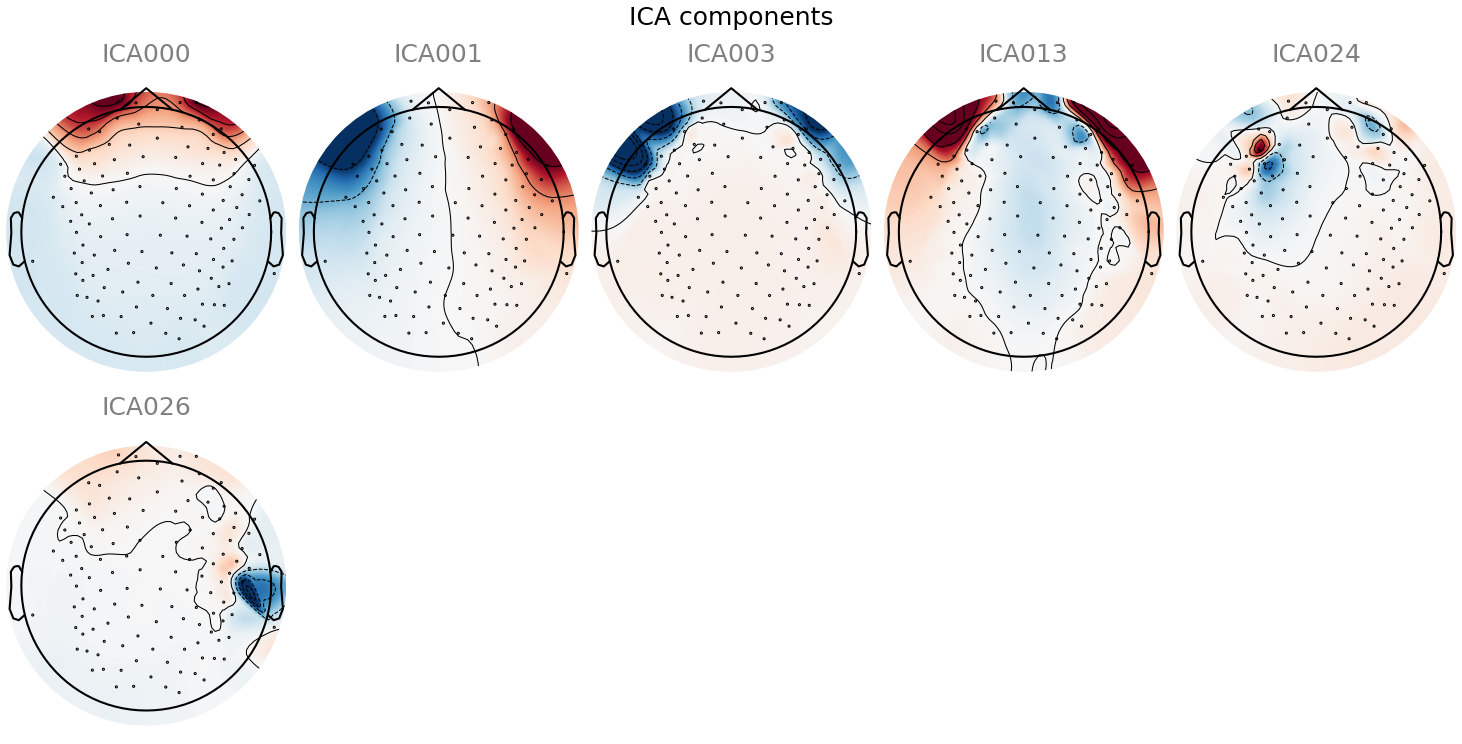

sub-02_task-oddball_qc.png


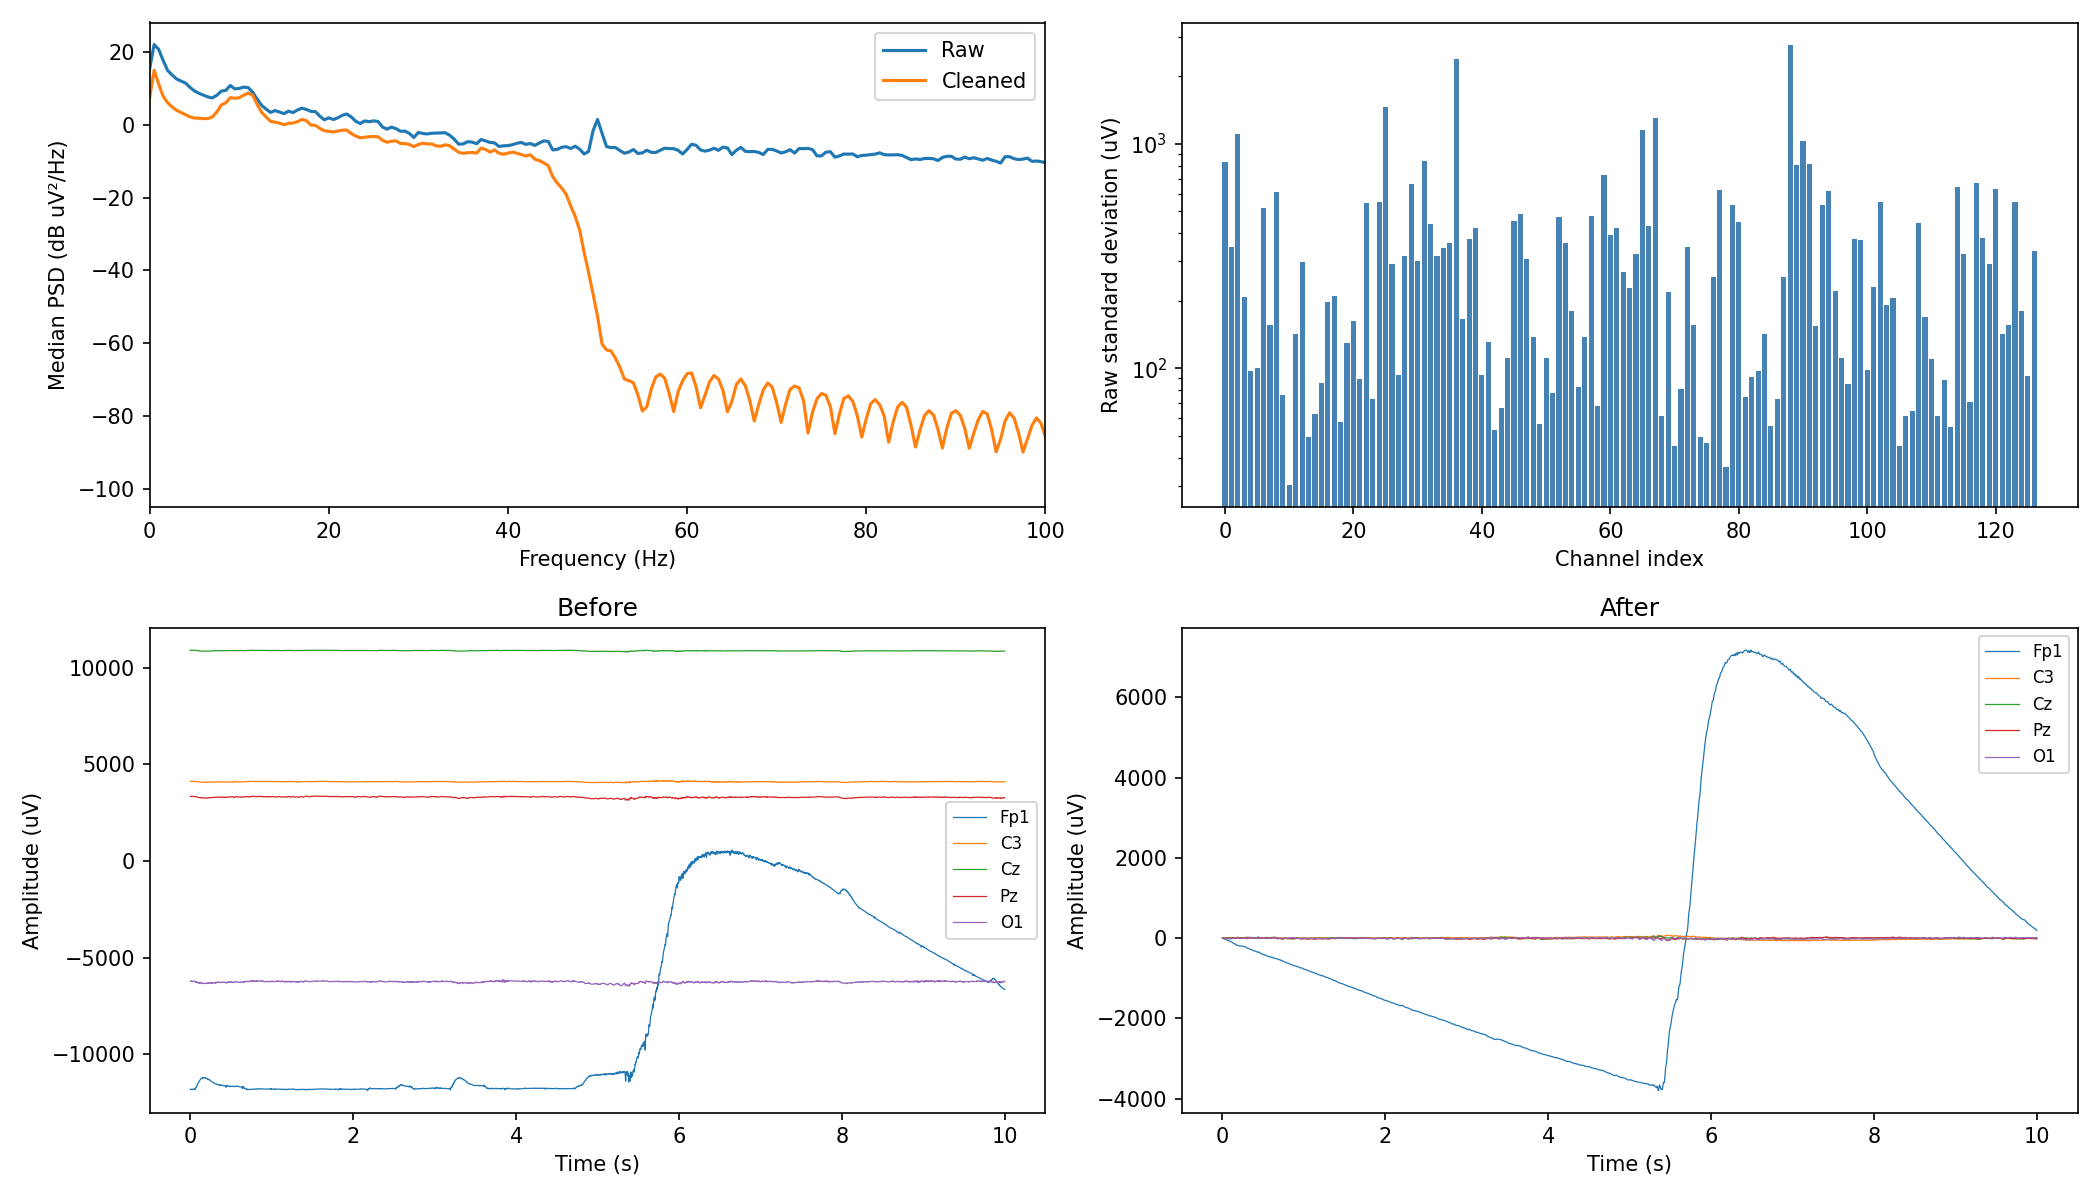

sub-03_task-oddball_epoch_qc.png


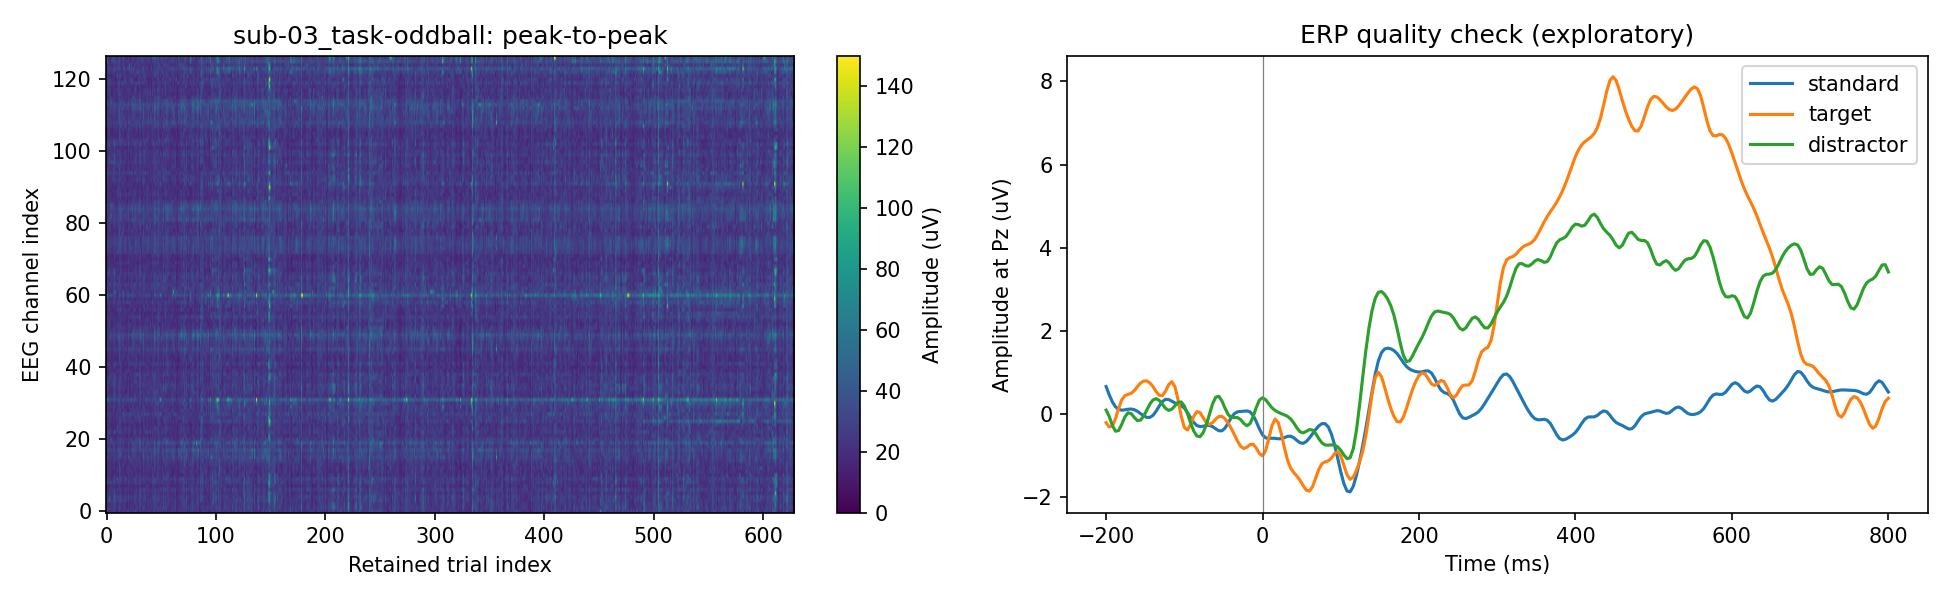

sub-03_task-oddball_excluded_ics_0.png


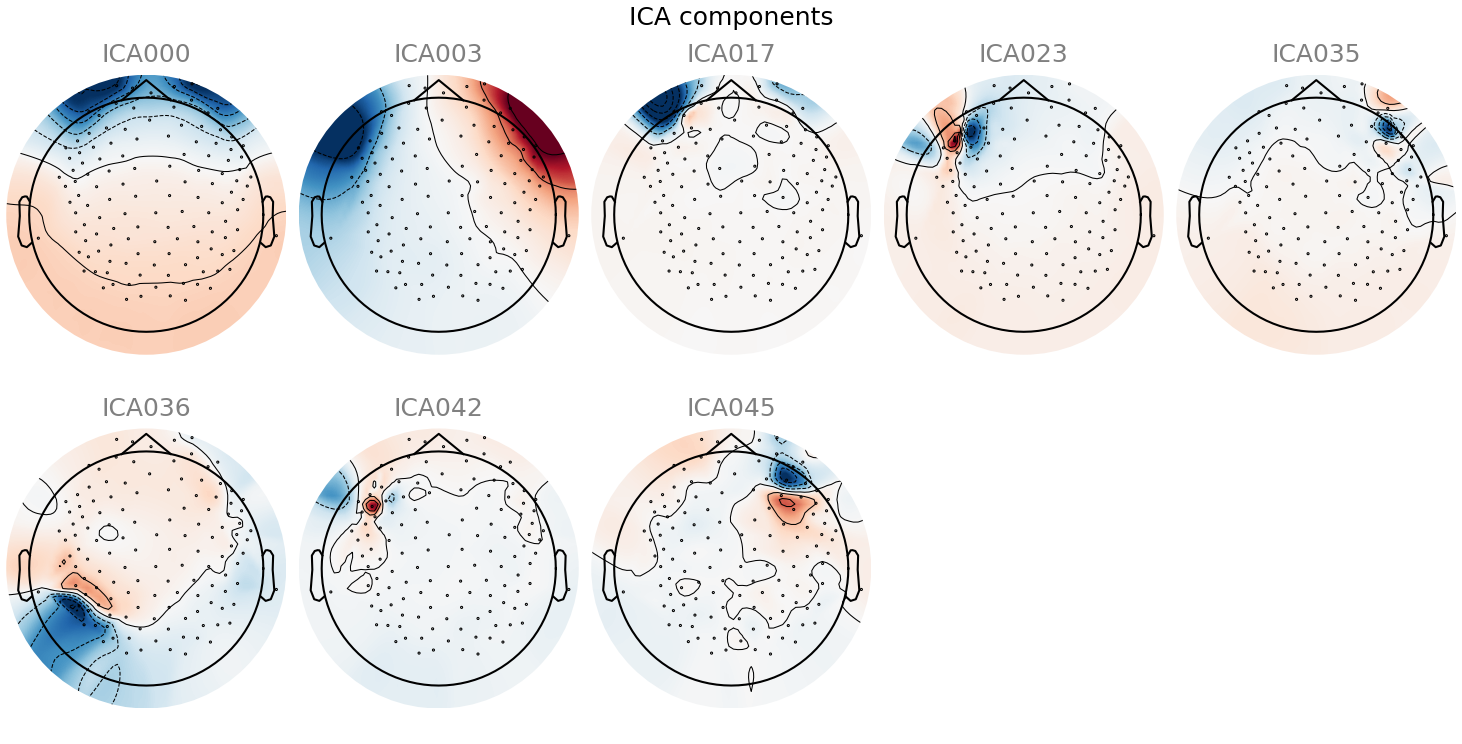

sub-03_task-oddball_qc.png


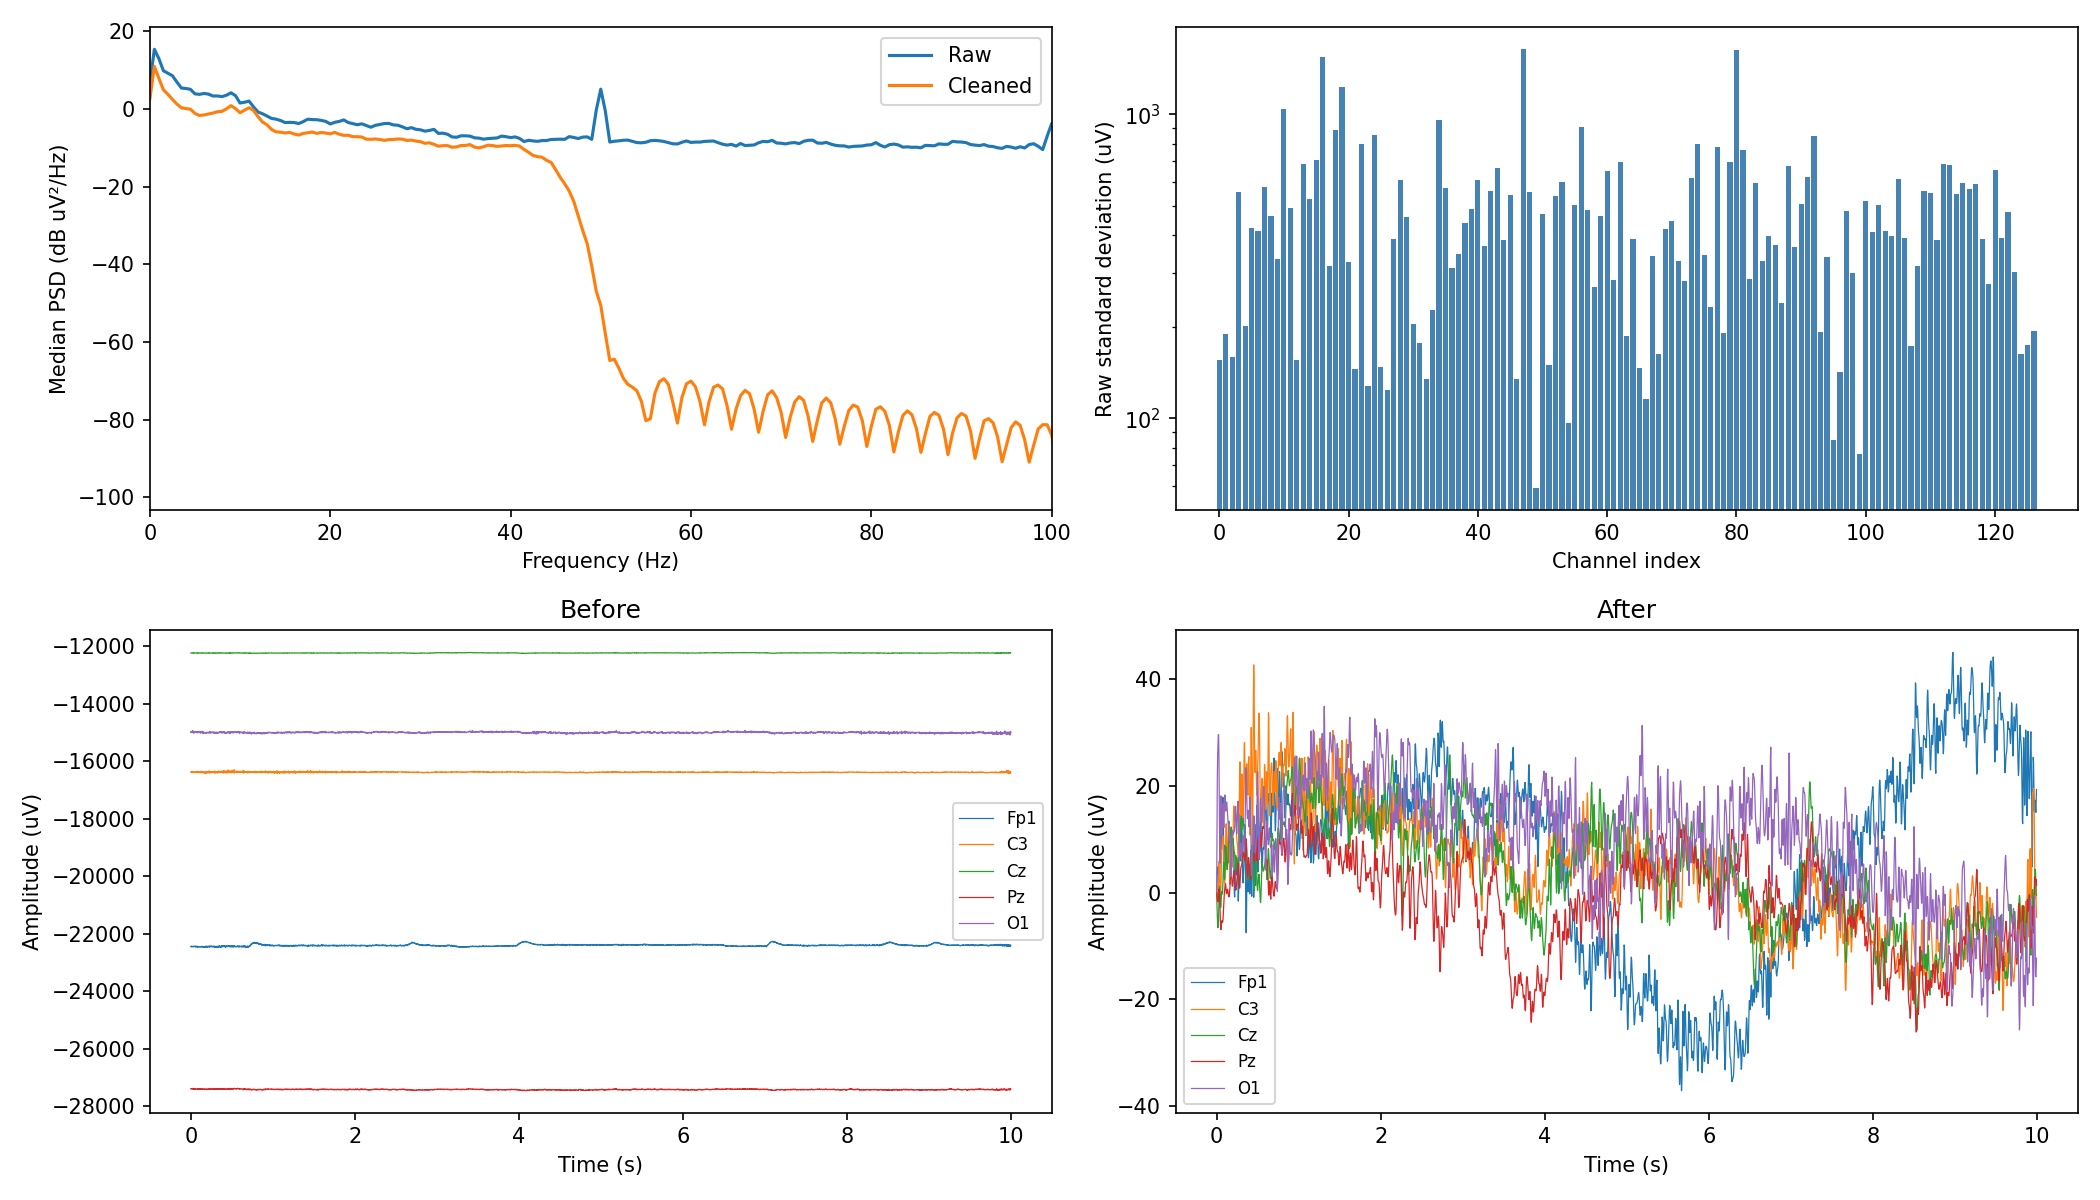

sub-04_task-oddball_epoch_qc.png


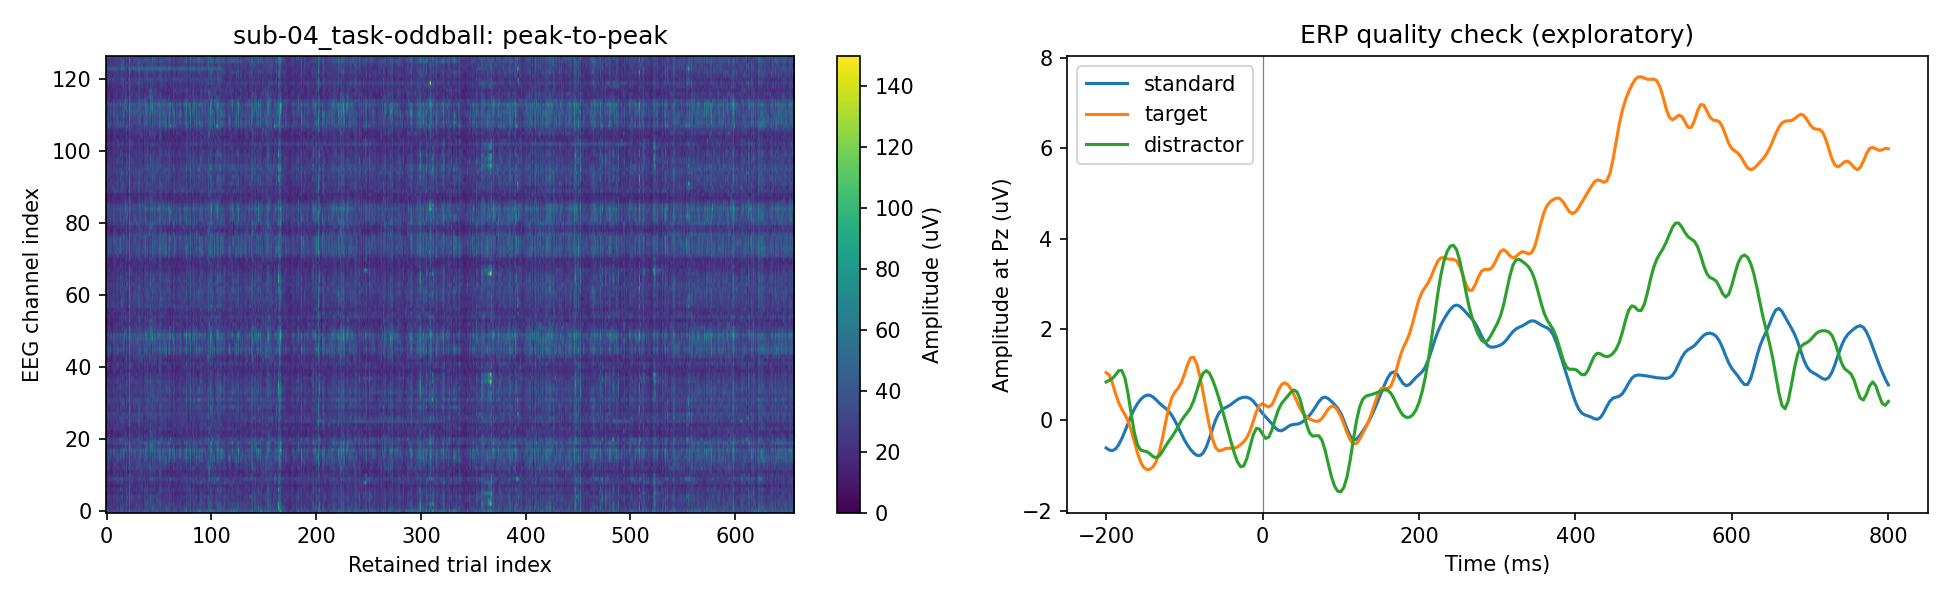

sub-04_task-oddball_excluded_ics_0.png


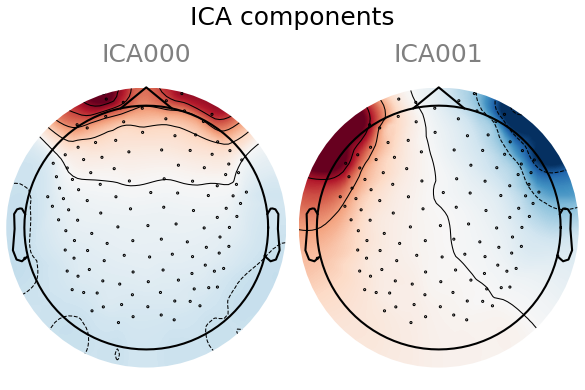

sub-04_task-oddball_qc.png


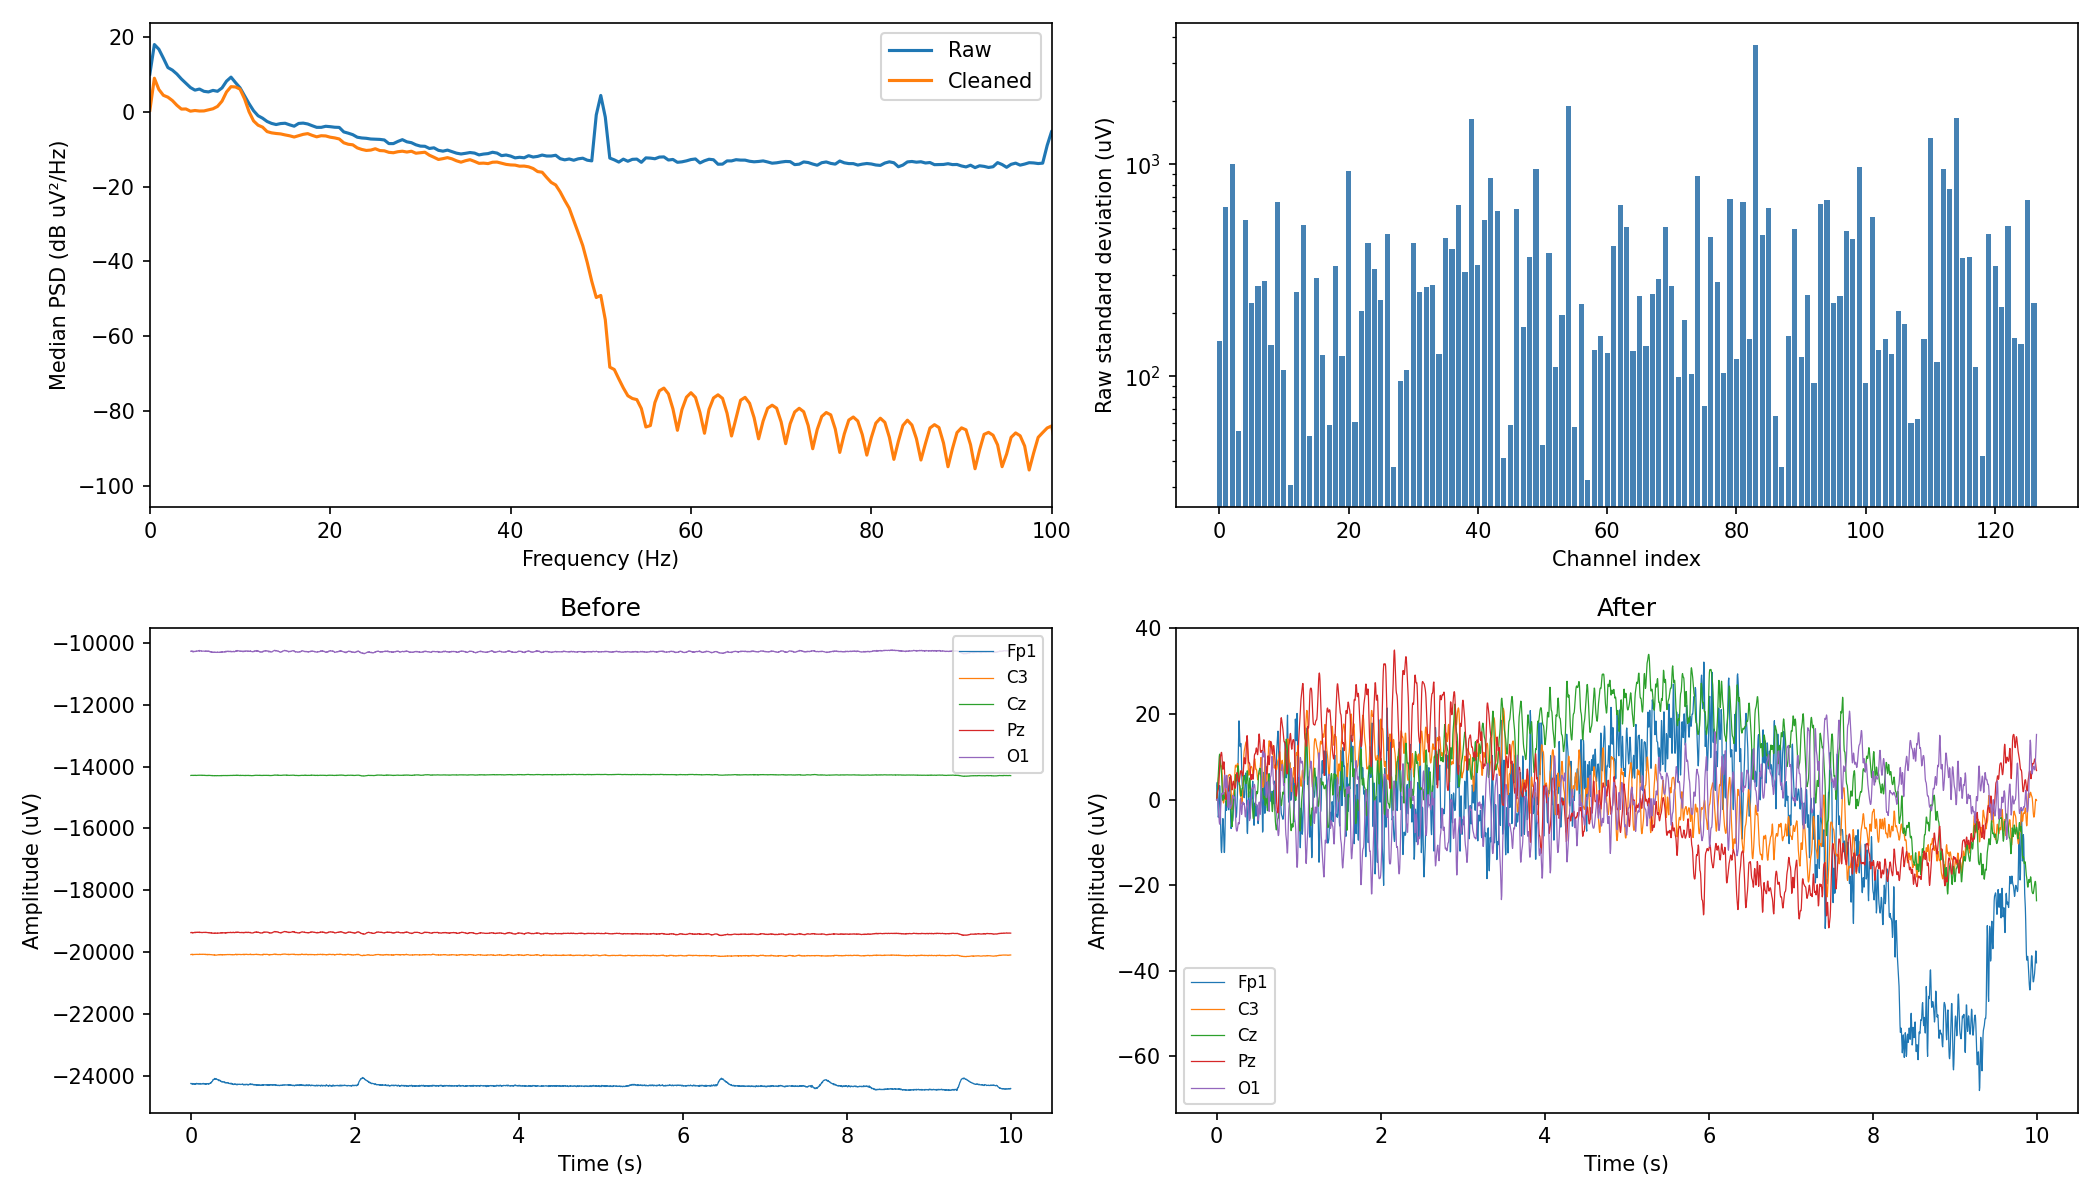

sub-05_task-oddball_epoch_qc.png


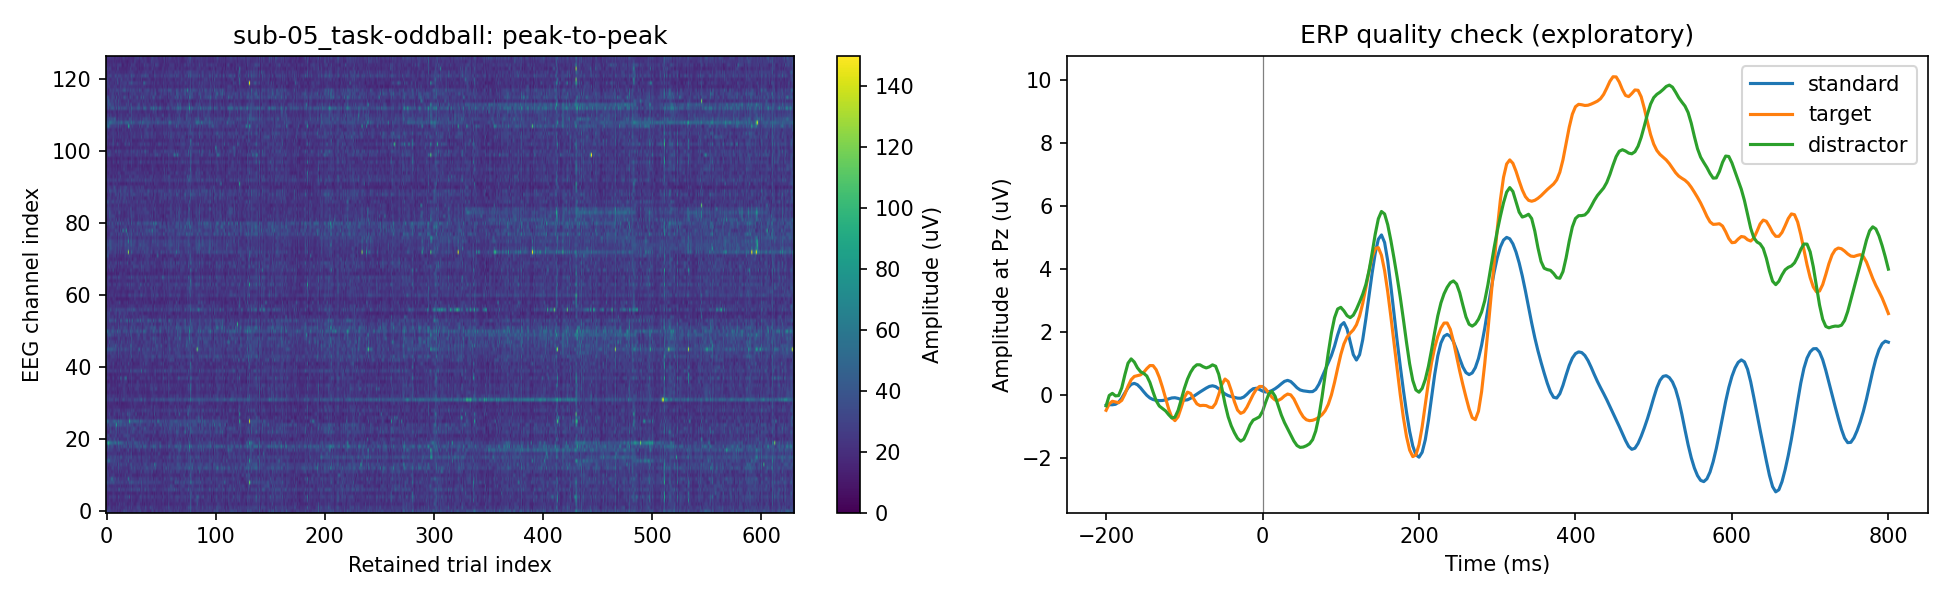

sub-05_task-oddball_excluded_ics_0.png


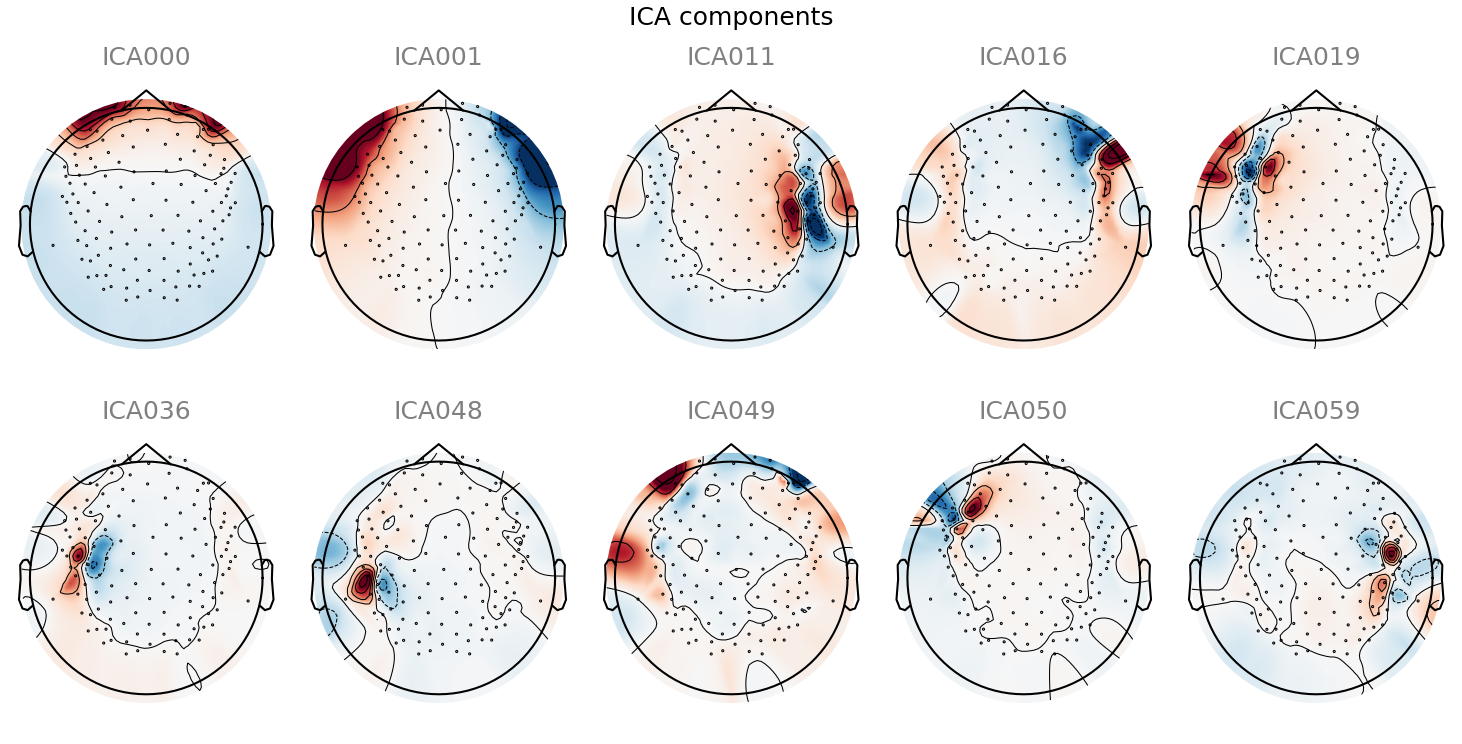

sub-05_task-oddball_qc.png


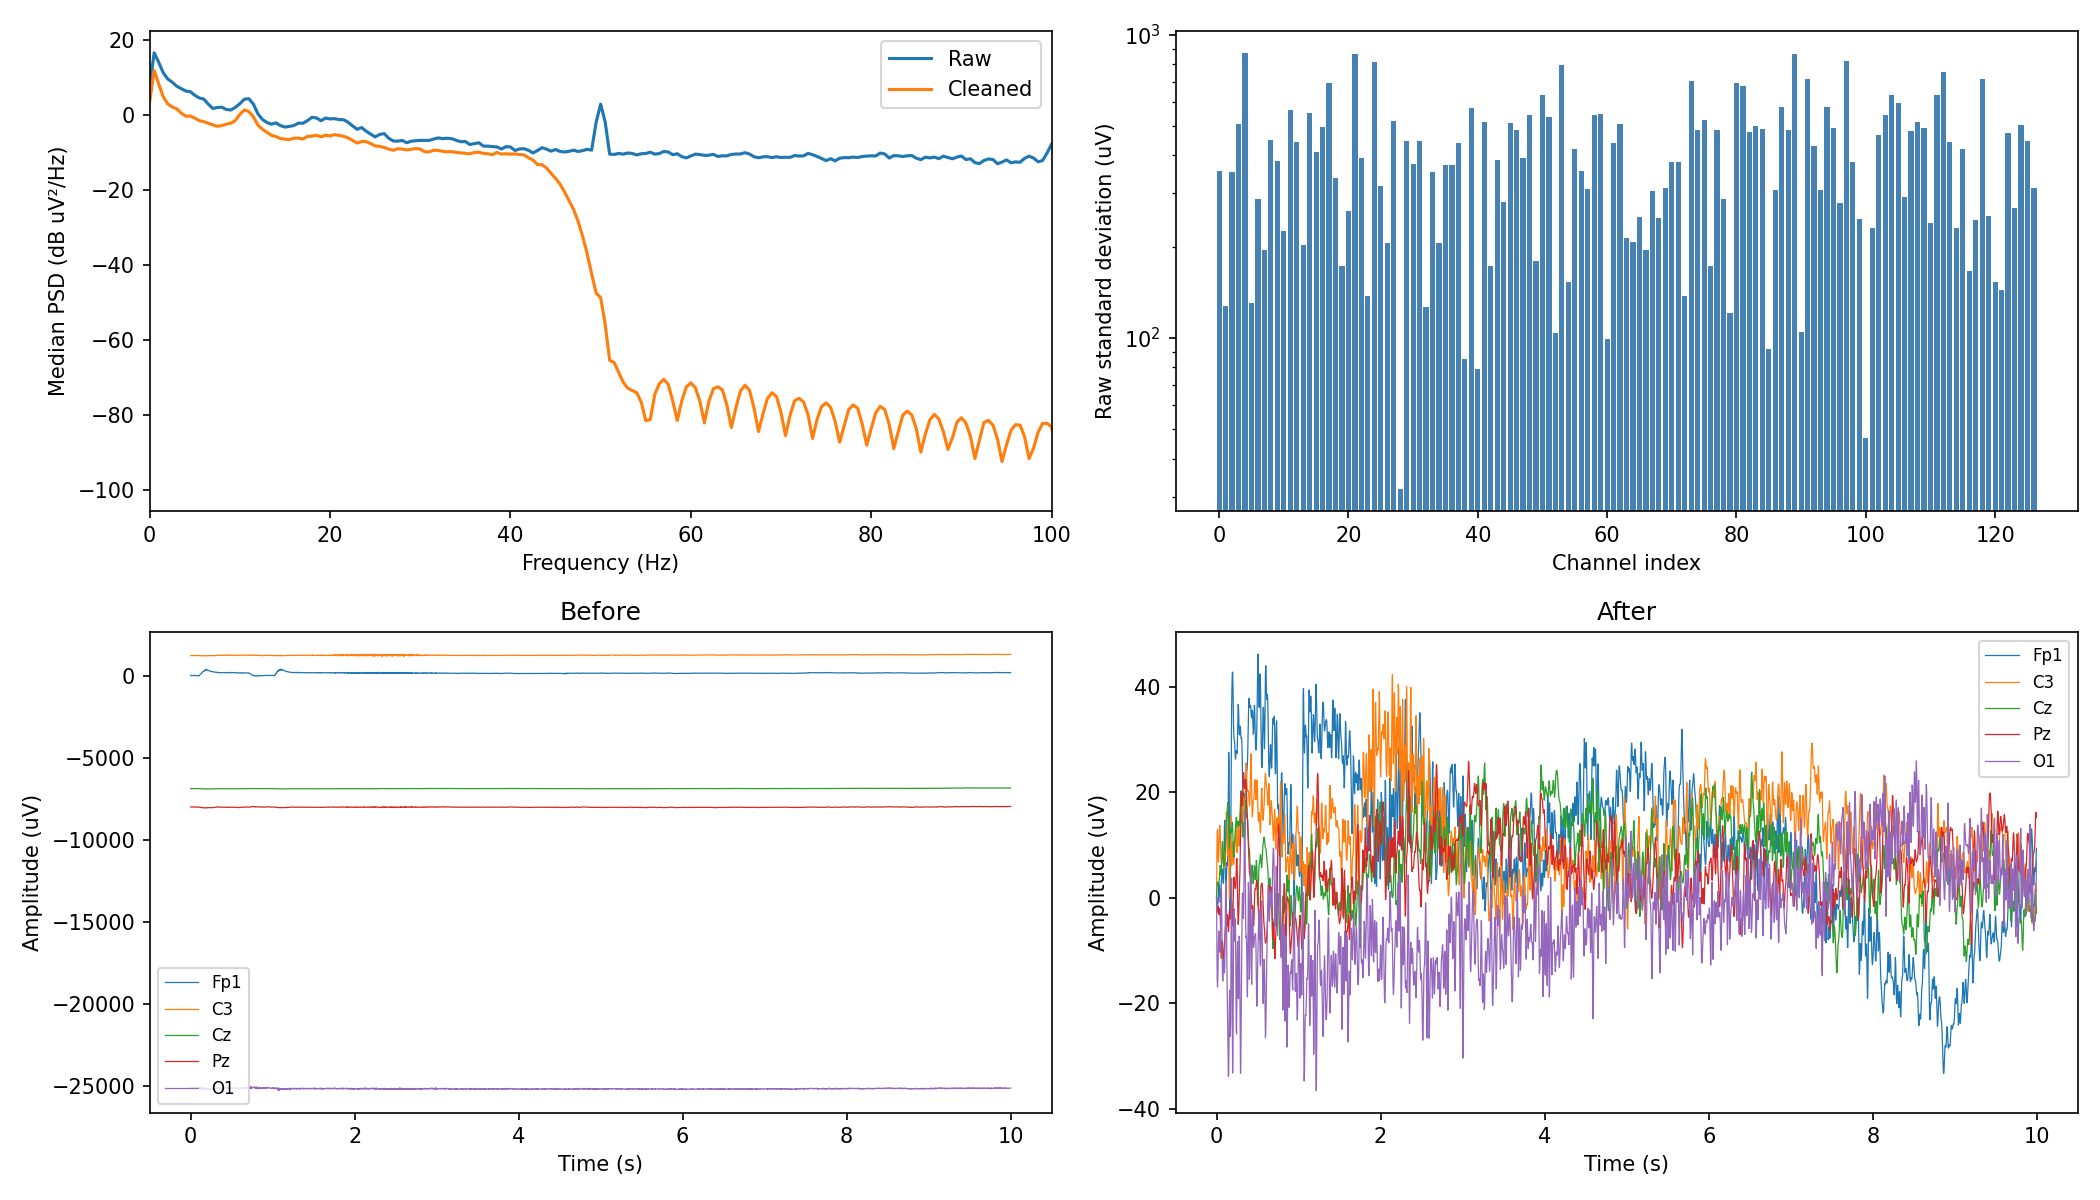

In [5]:
save_epoch_qc(ROOT, CONFIG, SUBJECTS)
display(pd.read_csv(ROOT / 'results/preproc_log.csv'))
qc_dir = ROOT / 'figures/preprocessing'
for subject in SUBJECTS:
    for path in sorted(qc_dir.glob(f'sub-{subject}_task-oddball_*.png')):
        print(path.name)
        display(Image(filename=str(path)))

## Ghi nhận kiểm tra bằng mắt
Kết quả lần chạy này đã được Codex xem các hình QC tổng hợp, chưa thay cho kiểm tra tương tác từng kênh. Log ghi `summary_plots_reviewed`. Nếu chạy lại với `overwrite=True`, trạng thái trở về `pending` và phải xem lại hình.
